
# One-Class SVM versus One-Class SVM using Stochastic Gradient Descent

This example shows how to approximate the solution of
:class:`sklearn.svm.OneClassSVM` in the case of an RBF kernel with
:class:`sklearn.linear_model.SGDOneClassSVM`, a Stochastic Gradient Descent
(SGD) version of the One-Class SVM. A kernel approximation is first used in
order to apply :class:`sklearn.linear_model.SGDOneClassSVM` which implements a
linear One-Class SVM using SGD.

Note that :class:`sklearn.linear_model.SGDOneClassSVM` scales linearly with
the number of samples whereas the complexity of a kernelized
:class:`sklearn.svm.OneClassSVM` is at best quadratic with respect to the
number of samples. It is not the purpose of this example to illustrate the
benefits of such an approximation in terms of computation time but rather to
show that we obtain similar results on a toy dataset.


In [ ]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

In [1]:
import matplotlib
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM
from sklearn.pipeline import make_pipeline
from sklearn.svm import OneClassSVM

font = {"weight": "normal", "size": 15}

matplotlib.rc("font", **font)

random_state = 42
rng = np.random.RandomState(random_state)

# Generate train data
X = 0.3 * rng.randn(500, 2)# datos de entrenamiento generados a partir de una distribución normal con media 0 y desviación estándar 0.3
X_train = np.r_[X + 2, X - 2]# combinación de dos conjuntos de datos desplazados para crear una distribución bimodal
# Generate some regular novel observations
X = 0.3 * rng.randn(20, 2)# datos de prueba generados a partir de una distribución normal con media 0 y desviación estándar 0.3
X_test = np.r_[X + 2, X - 2]# combinación de dos conjuntos de datos desplazados para crear una distribución bimodal
# Generate some abnormal novel observations
X_outliers = rng.uniform(low=-4, high=4, size=(20, 2))# datos de outliers generados a partir de una distribución uniforme en el rango [-4, 4]

# OCSVM hyperparameters
nu = 0.05# proporción de outliers esperados en los datos
gamma = 2.0# parámetro del kernel RBF que controla la influencia de cada punto de entrenamiento

# Fit the One-Class SVM
clf = OneClassSVM(gamma=gamma, kernel="rbf", nu=nu)
clf.fit(X_train)# ajuste del modelo a los datos de entrenamiento
y_pred_train = clf.predict(X_train)# predicción en los datos de entrenamiento
y_pred_test = clf.predict(X_test)# predicción en los datos de prueba
y_pred_outliers = clf.predict(X_outliers)# predicción en los datos de outliers
n_error_train = y_pred_train[y_pred_train == -1].size# número de errores en los datos de entrenamiento
n_error_test = y_pred_test[y_pred_test == -1].size# número de errores en los datos de prueba
n_error_outliers = y_pred_outliers[y_pred_outliers == 1].size# número de errores en los datos de outliers

# Fit the One-Class SVM using a kernel approximation and SGD
transform = Nystroem(gamma=gamma, random_state=random_state)# aproximación del núcleo utilizando el método de Nystroem
#gamma=gamma establece el parámetro del kernel RBF
clf_sgd = SGDOneClassSVM(# clasificador SGD para One-Class SVM
    nu=nu, shuffle=True, fit_intercept=True, random_state=random_state, tol=1e-4
    #nu=nu establece la proporción de outliers esperados en los datos
    #shuffle=True asegura que los datos se mezclen antes de cada época de entrenamiento
    #fit_intercept=True asegura que el modelo tenga un término independiente
    #tol=1e-4 establece la tolerancia para el criterio de parada del optimizador SGD
)

pipe_sgd = make_pipeline(transform, clf_sgd)# creación de una pipeline que primero aplica la aproximación del núcleo y luego el clasificador SGD
pipe_sgd.fit(X_train)# ajuste del modelo a los datos de entrenamiento
y_pred_train_sgd = pipe_sgd.predict(X_train)# predicción en los datos de entrenamiento
y_pred_test_sgd = pipe_sgd.predict(X_test)# predicción en los datos de prueba
y_pred_outliers_sgd = pipe_sgd.predict(X_outliers)# predicción en los datos de outliers
n_error_train_sgd = y_pred_train_sgd[y_pred_train_sgd == -1].size# número de errores en los datos de entrenamiento
n_error_test_sgd = y_pred_test_sgd[y_pred_test_sgd == -1].size# número de errores en los datos de prueba
n_error_outliers_sgd = y_pred_outliers_sgd[y_pred_outliers_sgd == 1].size# número de errores en los datos de outliers

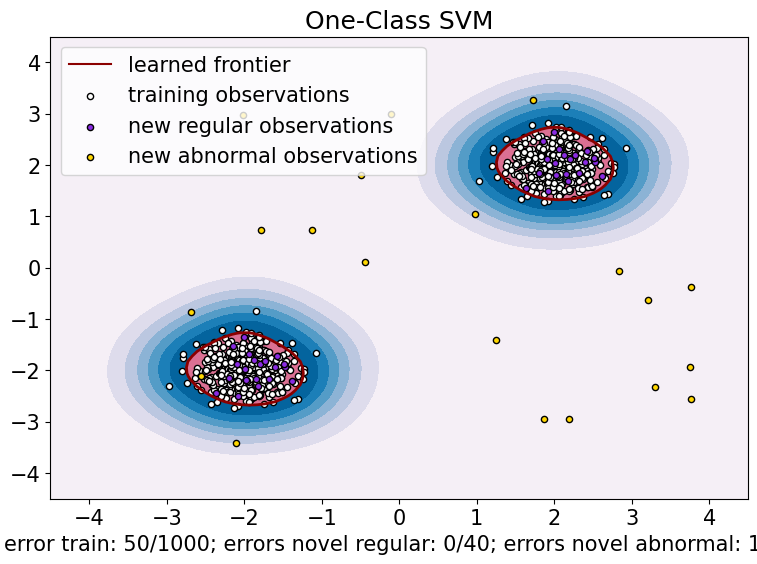

In [2]:
from sklearn.inspection import DecisionBoundaryDisplay

_, ax = plt.subplots(figsize=(9, 6))

xx, yy = np.meshgrid(np.linspace(-4.5, 4.5, 50), np.linspace(-4.5, 4.5, 50))# creación de una cuadrícula de puntos para evaluar la frontera de decisión
X = np.concatenate([xx.ravel().reshape(-1, 1), yy.ravel().reshape(-1, 1)], axis=1)# creación de una matriz de puntos 2D a partir de la cuadrícula
#reshape(-1, 1) convierte los arrays xx y yy en vectores columna    
#ravel() aplana los arrays 2D en 1D
#concatenate combina los vectores columna en una matriz de puntos 2D
DecisionBoundaryDisplay.from_estimator(#despliegue de la frontera de decisión del clasificador One-Class SVM
    clf,# clasificador ajustado
    X,# puntos de datos para evaluar la frontera de decisión
    response_method="decision_function",# método para calcular la respuesta del clasificador
    plot_method="contourf",# método de trazado para la frontera de decisión
    ax=ax,# eje donde se dibuja la frontera
    cmap="PuBu",# mapa de colores para el trazado
)
DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    response_method="decision_function",
    plot_method="contour",
    ax=ax,
    linewidths=2,# grosor de las líneas del contorno
    colors="darkred",
    levels=[0],
)
DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    response_method="decision_function",
    plot_method="contourf",
    ax=ax,
    colors="palevioletred",# color para el área sombreada dentro de la frontera
    levels=[0, clf.decision_function(X).max()],
)

s = 20
b1 = plt.scatter(X_train[:, 0], X_train[:, 1], c="white", s=s, edgecolors="k")# puntos de datos de entrenamiento
b2 = plt.scatter(X_test[:, 0], X_test[:, 1], c="blueviolet", s=s, edgecolors="k")# puntos de datos de prueba
c = plt.scatter(X_outliers[:, 0], X_outliers[:, 1], c="gold", s=s, edgecolors="k")# puntos de datos anómalos

ax.set(
    title="One-Class SVM",
    xlim=(-4.5, 4.5),
    ylim=(-4.5, 4.5),
    xlabel=(
        f"error train: {n_error_train}/{X_train.shape[0]}; "# número de errores en los datos de entrenamiento
        f"errors novel regular: {n_error_test}/{X_test.shape[0]}; "# número de errores en los datos de prueba
        f"errors novel abnormal: {n_error_outliers}/{X_outliers.shape[0]}"# número de errores en los datos de outliers
    ),
)
_ = ax.legend(
    [mlines.Line2D([], [], color="darkred", label="learned frontier"), b1, b2, c],
    [
        "learned frontier",
        "training observations",
        "new regular observations",
        "new abnormal observations",
    ],
    loc="upper left",
)

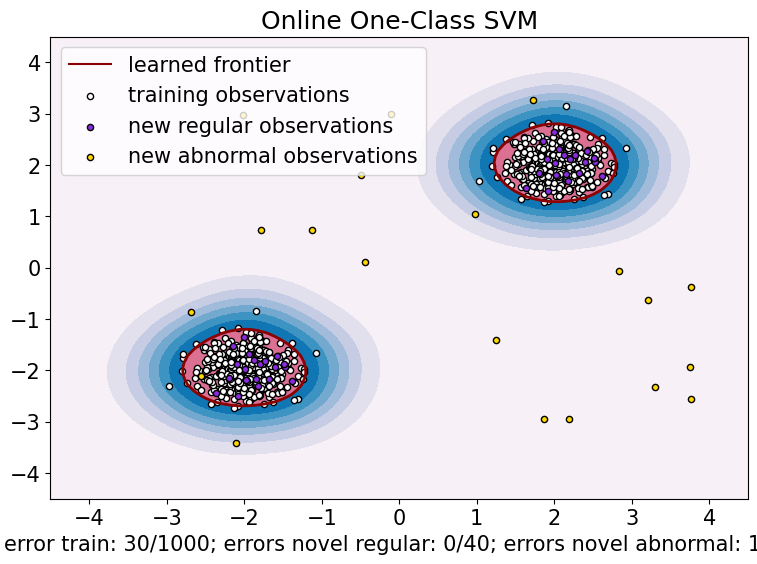

In [3]:
_, ax = plt.subplots(figsize=(9, 6))# creación de una nueva figura para el clasificador SGD One-Class SVM
# _, este subrayado indica que no se utilizará la variable devuelta, ax es el eje de la figura 

xx, yy = np.meshgrid(np.linspace(-4.5, 4.5, 50), np.linspace(-4.5, 4.5, 50))# creación de una cuadrícula de puntos para evaluar la frontera de decisión
X = np.concatenate([xx.ravel().reshape(-1, 1), yy.ravel().reshape(-1, 1)], axis=1)# creación de una matriz de puntos 2D a partir de la cuadrícula
DecisionBoundaryDisplay.from_estimator(#despliegue de la frontera de decisión del clasificador SGD One-Class SVM
    pipe_sgd,# pipeline ajustada
    X,# puntos de datos para evaluar la frontera de decisión
    response_method="decision_function",# método para calcular la respuesta del clasificador
    plot_method="contourf",# método de trazado para la frontera de decisión
    ax=ax,# eje donde se dibuja la frontera
    cmap="PuBu",# mapa de colores para el trazado
)
DecisionBoundaryDisplay.from_estimator(
    pipe_sgd,
    X,
    response_method="decision_function",
    plot_method="contour",
    ax=ax,
    linewidths=2,
    colors="darkred",
    levels=[0],# nivel del contorno que representa la frontera de decisión
)
DecisionBoundaryDisplay.from_estimator(
    pipe_sgd,
    X,
    response_method="decision_function",
    plot_method="contourf",
    ax=ax,
    colors="palevioletred",
    levels=[0, pipe_sgd.decision_function(X).max()],
)

s = 20
b1 = plt.scatter(X_train[:, 0], X_train[:, 1], c="white", s=s, edgecolors="k")
b2 = plt.scatter(X_test[:, 0], X_test[:, 1], c="blueviolet", s=s, edgecolors="k")
c = plt.scatter(X_outliers[:, 0], X_outliers[:, 1], c="gold", s=s, edgecolors="k")

ax.set(
    title="Online One-Class SVM",
    xlim=(-4.5, 4.5),
    ylim=(-4.5, 4.5),
    xlabel=(
        f"error train: {n_error_train_sgd}/{X_train.shape[0]}; "
        f"errors novel regular: {n_error_test_sgd}/{X_test.shape[0]}; "
        f"errors novel abnormal: {n_error_outliers_sgd}/{X_outliers.shape[0]}"
    ),
)
ax.legend(
    [mlines.Line2D([], [], color="darkred", label="learned frontier"), b1, b2, c],
    [
        "learned frontier",
        "training observations",
        "new regular observations",
        "new abnormal observations",
    ],
    loc="upper left",
)
plt.show()